In [1]:
# Experiment 06 — Shor's Algorithm: Factoring 15

In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from math import gcd
import numpy as np
from fractions import Fraction

In [3]:
# Number to factor
N = 15

# Choose a number coprime to N
a = 2

print("Number to factor:", N)
print("Chosen base:", a)
print("GCD:", gcd(a, N))

Number to factor: 15
Chosen base: 2
GCD: 1


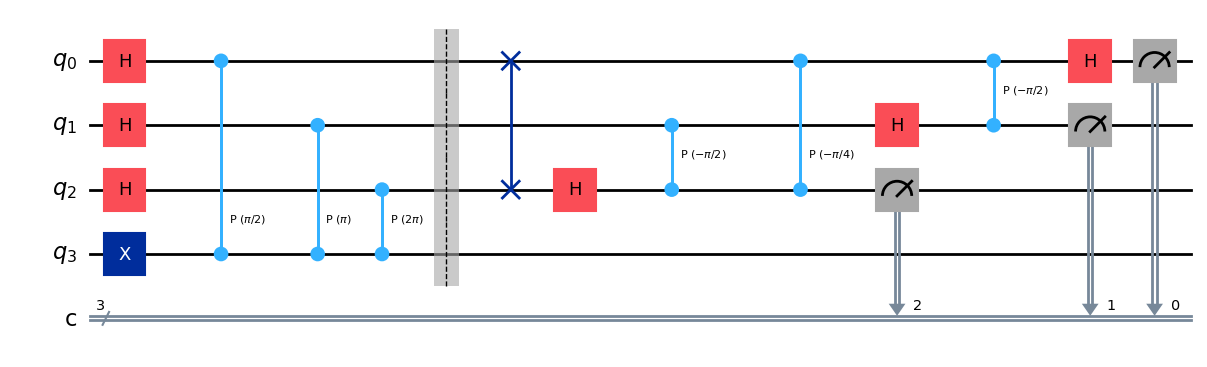

In [4]:
# Create three counting qubits and one target qubit
qc = QuantumCircuit(4, 3)

# Prepare the target in |1>
qc.x(3)

# Apply Hadamard gates to counting qubits
qc.h([0, 1, 2])

# Controlled powers of a period-four operation
qc.cp(np.pi / 2, 0, 3)
qc.cp(np.pi, 1, 3)
qc.cp(2 * np.pi, 2, 3)

qc.barrier()

# Apply inverse QFT
qc.swap(0, 2)

qc.h(2)
qc.cp(-np.pi / 2, 1, 2)
qc.cp(-np.pi / 4, 0, 2)

qc.h(1)
qc.cp(-np.pi / 2, 0, 1)

qc.h(0)

# Measure the counting qubits
qc.measure([0, 1, 2], [0, 1, 2])

# Display the circuit
display(qc.draw("mpl"))

In [5]:
# Run the circuit
simulator = AerSimulator()

result = simulator.run(
    transpile(qc, simulator),
    shots=1024,
    seed_simulator=42
).result()

counts = result.get_counts()

print("Measurement Counts:", counts)

Measurement Counts: {'011': 255, '010': 261, '100': 223, '111': 205, '110': 42, '101': 38}


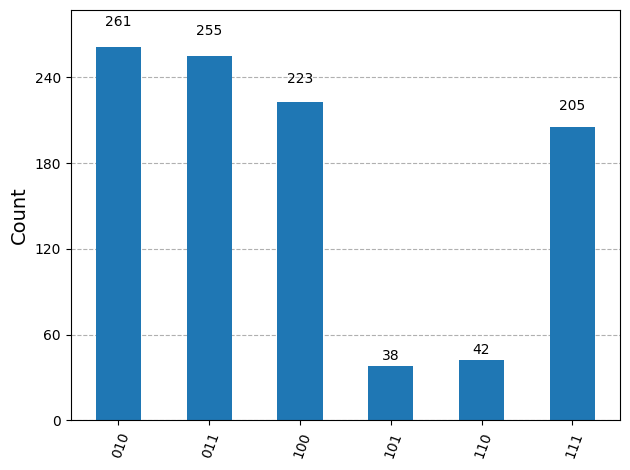

In [6]:
# Plot the measurement results
display(plot_histogram(counts))

In [7]:
# Find the most frequent measurement
measured = max(counts, key=counts.get)

# Convert the measurement into a phase
decimal_value = int(measured, 2)
phase = decimal_value / 8

# Estimate the period using fractions
fraction = Fraction(decimal_value, 8).limit_denominator(N)
r = fraction.denominator

print("Measured State:", measured)
print("Estimated Phase:", phase)
print("Fraction:", fraction)
print("Estimated Period:", r)

# Check the period using modular arithmetic
print("Period Verified:", pow(a, r, N) == 1)

Measured State: 010
Estimated Phase: 0.25
Fraction: 1/4
Estimated Period: 4
Period Verified: True


In [8]:
# Calculate the factors using the estimated period
if r % 2 == 0 and pow(a, r // 2, N) != N - 1:
    p = gcd(pow(a, r // 2) - 1, N)
    q = gcd(pow(a, r // 2) + 1, N)

    print("First Factor:", p)
    print("Second Factor:", q)
    print("Product:", p * q)
    print("Factorization Correct:", p * q == N)
else:
    print("This period does not give useful factors.")

First Factor: 3
Second Factor: 5
Product: 15
Factorization Correct: True
